# Task 2 · Notebook 01 — Exploratory Data Analysis

**Business question.** British Airways wants to know which customers are likely to complete a booking, so marketing can focus on the right people at the right time.

**Data.** `data/raw/customer_booking.csv` contains 50,000 booking records provided in the Forage British Airways job simulation. The target column `booking_complete` is 1 if the customer completed the booking and 0 if not.

**Goal of this notebook.** Understand the data before any modelling, covering quality issues, the balance between bookers and non-bookers, and which features look related to completing a booking.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_FILE = Path("data/raw/customer_booking.csv")
df = pd.read_csv(DATA_FILE, encoding="ISO-8859-1")

print(f"{len(df):,} rows, {df.shape[1]} columns")
print("Missing values:", df.isna().sum().sum())
print("Exact duplicate rows:", df.duplicated().sum())
df.head()

50,000 rows, 14 columns
Missing values: 0
Exact duplicate rows: 719


,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


In [2]:
booking_rate = df["booking_complete"].mean()
print(f"Booking rate: {booking_rate:.1%}  ({df['booking_complete'].sum():,} of {len(df):,})")

df["booking_complete"].value_counts().rename({0: "did not book", 1: "booked"})


Booking rate: 15.0%  (7,478 of 50,000)


booking_complete
did not book    42522
booked           7478
Name: count, dtype: int64

In [3]:
features = df.columns.drop("booking_complete")

same_features = df.duplicated(subset=features).sum()
print(f"Rows identical in every column: {df.duplicated().sum()}")
print(f"Rows identical in all features (ignoring the outcome): {same_features}")

conflicts = df.groupby(list(features))["booking_complete"].nunique()
print(f"Groups of identical customers with DIFFERENT outcomes: {(conflicts > 1).sum()}")

Rows identical in every column: 719
Rows identical in all features (ignoring the outcome): 727
Groups of identical customers with DIFFERENT outcomes: 8


**Duplicates.** 719 rows are exact copies of another row. Only 8 groups of identical-looking customers have different outcomes, so most duplicates are probably repeated records rather than different people.

**Decision.** Remove the 719 exact duplicates before modelling. If left in, the same record could appear in both the training and test sets, so the model would be tested on rows it had already seen and its score would be inflated. The 8 conflicting groups are kept, because different outcomes mean they are genuinely different customers.

In [4]:
df = df.drop_duplicates().reset_index(drop=True)
print(f"After removing exact duplicates: {len(df):,} rows, booking rate {df['booking_complete'].mean():.1%}")

After removing exact duplicates: 49,281 rows, booking rate 15.0%


## Which customer choices are linked to completing a booking?

Each bar shows the booking rate for one group. The dashed line is the overall rate (15%), so bars to the right of it book more often than average.

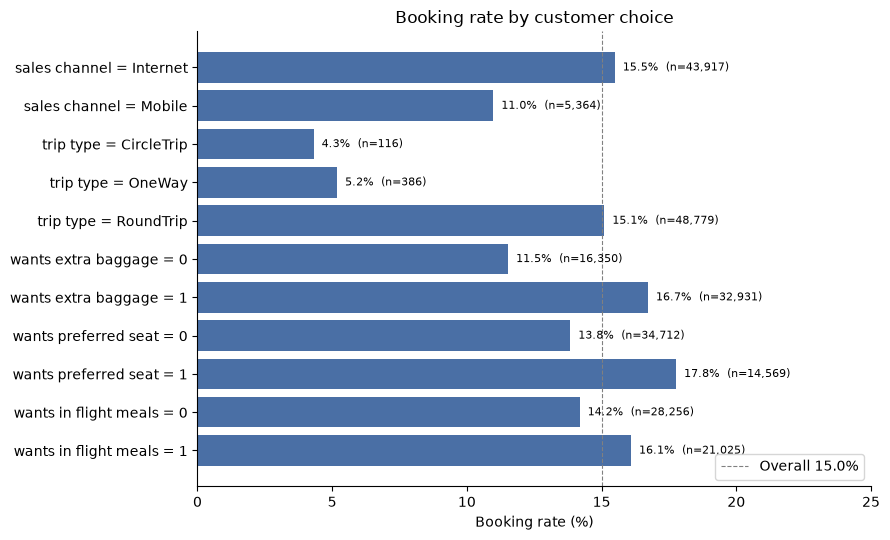

In [5]:
overall = df["booking_complete"].mean()

rows = []
for col in ["sales_channel", "trip_type", "wants_extra_baggage", "wants_preferred_seat", "wants_in_flight_meals"]:
    for value, grp in df.groupby(col):
        label = f"{col.replace('_', ' ')} = {value}"
        rows.append({"group": label, "booking_rate": grp["booking_complete"].mean(), "customers": len(grp)})
rates = pd.DataFrame(rows).iloc[::-1]          # reverse so the first feature appears at the top

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(rates["group"], rates["booking_rate"] * 100, color="#4a6fa5")
ax.axvline(overall * 100, color="grey", linestyle="--", linewidth=0.8, label=f"Overall {overall:.1%}")
for i, (r, n) in enumerate(zip(rates["booking_rate"], rates["customers"])):
    ax.text(r * 100 + 0.3, i, f"{r:.1%}  (n={n:,})", va="center", fontsize=8)
ax.set_xlabel("Booking rate (%)")
ax.set_title("Booking rate by customer choice")
ax.set_xlim(0, 25)
ax.legend(loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Observations**
- **Add-ons signal intent.** Customers who add extra baggage (16.7% vs 11.5%) or a preferred seat (17.8% vs 13.8%) book more often, plausibly because they are further into planning a real trip.
- **Trip type** shows the largest gap (round trips 15.1% vs one-way 5.2%), but one-way and circle trips are only about 1% of customers, so this affects few people.
- **Mobile** customers book less often than Internet customers (11.0% vs 15.5%).
- These differences are real but modest. No single feature separates bookers from non-bookers well, which suggests prediction will be difficult.

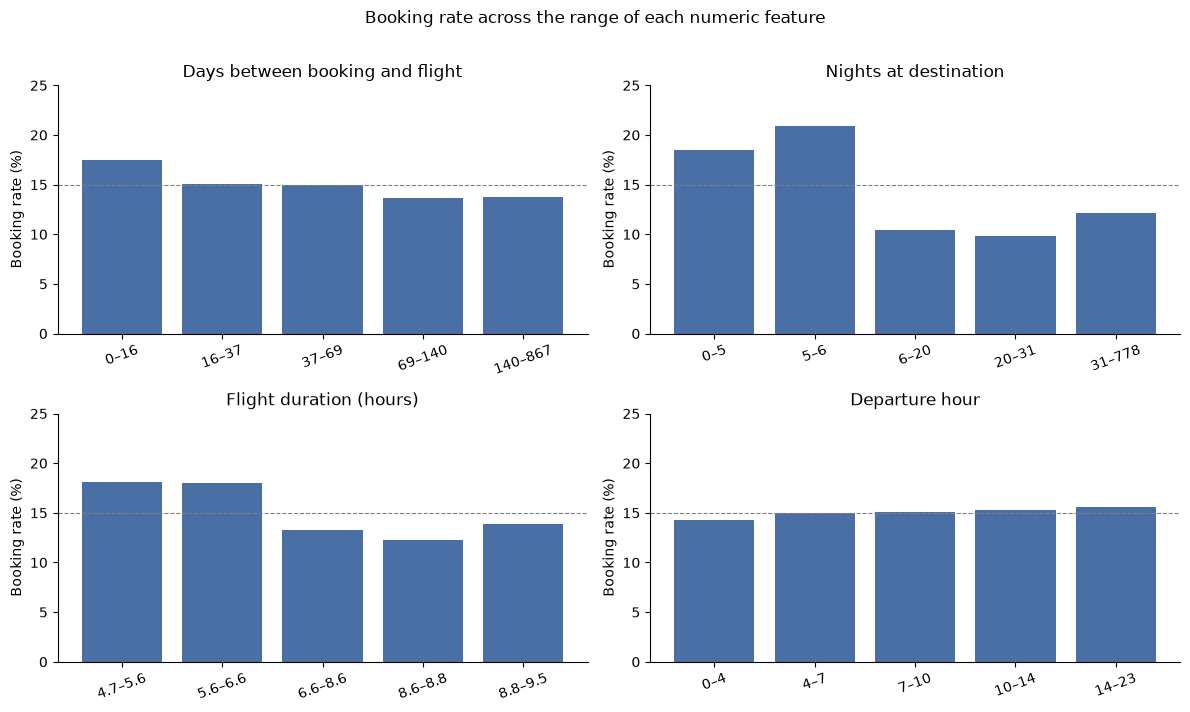

In [6]:
numeric = {
    "purchase_lead": "Days between booking and flight",
    "length_of_stay": "Nights at destination",
    "flight_duration": "Flight duration (hours)",
    "flight_hour": "Departure hour",
}

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (col, title) in zip(axes.flat, numeric.items()):
    bins = pd.qcut(df[col], 5, duplicates="drop")                  # 5 groups of roughly equal size
    rate = df.groupby(bins, observed=True)["booking_complete"].mean() * 100
    ax.bar(range(len(rate)), rate.values, color="#4a6fa5")
    ax.set_xticks(range(len(rate)))
    fmt = "{:.1f}" if col == "flight_duration" else "{:.0f}"
    ax.set_xticklabels([f"{fmt.format(max(iv.left, 0))}–{fmt.format(iv.right)}" for iv in rate.index], rotation=20)
    ax.axhline(overall * 100, color="grey", linestyle="--", linewidth=0.8)
    ax.set_title(title)
    ax.set_ylabel("Booking rate (%)")
    ax.set_ylim(0, 25)
    ax.spines[["top", "right"]].set_visible(False)

plt.suptitle("Booking rate across the range of each numeric feature", y=1.01)
plt.tight_layout()
plt.show()

**Observations**
- **Booking soon after searching completes more often.** Customers booking within 16 days of the flight complete 17.5% of the time, compared with about 13.7% for those booking more than 69 days ahead. This **contradicts** the original project's claim that booking far in advance signals commitment.
- **Shorter flights complete more often** (≈18% for 5–7 hour flights vs 12–14% for longer ones), again the **opposite** of the original claim about long-haul bookings.
- **Short stays complete most often.** Trips of up to 6 nights book at 18–21%, roughly double the ≈10% for stays of 7–31 nights.
- **Departure hour makes no difference.**

These are associations only. Some may overlap (short flights may tend to be short stays), which the model will untangle.

In [7]:
by_country = (
    df.groupby("booking_origin")["booking_complete"]
      .agg(booking_rate="mean", customers="size")
      .sort_values("customers", ascending=False)
)
print(f"{df['booking_origin'].nunique()} countries, {(by_country['customers'] < 50).sum()} of them with fewer than 50 customers\n")
by_country.head(12).assign(booking_rate=lambda t: (t["booking_rate"] * 100).round(1))

104 countries, 78 of them with fewer than 50 customers



,booking_rate,customers
booking_origin,,
Australia,5.1,17691
Malaysia,34.5,7055
South Korea,10.2,4502
Japan,12.4,3819
China,20.8,3284
Indonesia,26.3,2317
Taiwan,10.8,2042
Thailand,23.3,1993
India,10.2,1258


**Observations**
- **Country of booking is the strongest pattern in the data.** Australia, the largest market (36% of customers), converts at only 5.1%, while Malaysia converts at 34.5%. Australia and New Zealand are low, while several Southeast Asian markets (Singapore, Indonesia, Thailand) are high.
- **Most countries are tiny.** 78 of 104 countries have fewer than 50 customers, so their individual booking rates are unreliable. The model will need to group rare countries together rather than treat each one separately.
- **The data covers an Asia-Pacific network.** Routes such as AKL–DEL (Auckland–Delhi) and the mix of booking countries suggest this is not a typical BA network out of London, so findings describe this dataset rather than BA's business as a whole.

We cannot tell from this data *why* countries differ (pricing, competition, how the website is used in each market), so this is a lead for the business to investigate rather than an explanation.

In [8]:
OUT_FILE = Path("data/processed/bookings_clean.csv")
OUT_FILE.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(OUT_FILE, index=False)
print(f"Saved {len(df):,} de-duplicated bookings to {OUT_FILE}")

Saved 49,281 de-duplicated bookings to data\processed\bookings_clean.csv


## Summary

**Data quality.** 50,000 records with no missing values. 719 exact duplicates were removed (49,281 remain), so the same record cannot appear in both training and test data.

**Class imbalance.** Only 15% of customers complete a booking. Accuracy alone would be misleading (a model predicting "no booking" for everyone is 85% accurate), so models will be judged on measures that focus on finding bookers, such as recall, precision and PR AUC.

**What is linked to booking**
1. **Booking country** is by far the strongest pattern, ranging from 5% (Australia, the largest market) to 35% (Malaysia).
2. **Short stays** (up to 6 nights) book about twice as often as longer stays.
3. **Shorter flights** and **bookings made close to departure** complete more often, the opposite of what the original version of this project claimed.
4. **Add-ons** (extra baggage, preferred seat) are linked to modestly higher booking rates.
5. **Departure hour** makes little difference.

**Implications for modelling**
- No single feature separates bookers from non-bookers strongly, so prediction will be difficult and modest scores are expected.
- 78 of 104 countries have fewer than 50 customers, so rare countries must be grouped together.
- `route` has 799 different values and needs a similar approach.

**Next.** Notebook 02 prepares the features and trains the models.